# Indoor Location Prediction Using Wi-Fi Signals (Phase 2: Deep Learning)

AML Project 9, Section D, Team T108

Team: Rishi Raj, Aditya Samadhiya, Yash Yadav, Kaustubh Ranjan Mishra, Yash Raj

Phase 1 compared Linear/Logistic Regression, k-NN and Random Forest. Each of those models learns
building, floor and position separately. The per-building Random Forest reached 99.8% building,
91.3% floor and 9.37 m mean error on the official test set.

Phase 2 trains one neural network for all three targets at once: a shared trunk with three output heads
(building, floor, coordinates). The comparison with Phase 1 uses the same split (official test file,
cross-validation by user) and the same metrics.

The network code is in `src/indoorloc/deep.py`. Settings were chosen by cross-validation only; see
`docs/dl_architecture.md` for what was tried.

In [1]:
import sys, json
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from sklearn.metrics import confusion_matrix

from indoorloc.data import load_splits, split_xy
from indoorloc.deep import MultitaskModel, MultitaskMLP
from indoorloc.metrics import summarize, positioning_errors, hierarchical_breakdown, per_group_error

RES = Path("../results")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)
torch.manual_seed(42)

## 1. Data and the Phase 1 baseline

In [2]:
train, test, report = load_splits()
Xtr, ytr, mtr = split_xy(train)
Xte, yte, mte = split_xy(test)
print(report)
print("train", Xtr.shape, "| test", Xte.shape)

phase1 = pd.read_csv(RES / "test_metrics.csv")
phase1[["model", "building_acc", "floor_acc", "mean_error_m", "median_error_m"]]

{'rows_in': 19937, 'duplicates_dropped': 637, 'empty_scans_dropped': 73, 'rows_out': 19227}
train (19227, 520) | test (1111, 520)


,model,building_acc,floor_acc,mean_error_m,median_error_m
0,Linear + Logistic Regression,1.000,0.887,51.995,37.528
1,k-NN,0.997,0.901,8.691,5.355
2,Random Forest,0.998,0.909,10.222,7.629
3,Random Forest (per-building),0.998,0.913,9.366,7.073


## 2. The network

Input: the 465 signal values after the Phase 1 preprocessing (+100 replaced by -105), scaled to 0 to 1.
Trunk: fully connected layers with ReLU and dropout. Three heads: building (3 outputs), floor (5 outputs),
coordinates (2 outputs). Loss = cross-entropy(building) + cross-entropy(floor) + w * MSE(scaled coordinates).
Adam optimiser, early stopping on a validation part of the training data.

In [3]:
settings = json.load(open(RES / "dl_best.json"))
settings

{'hidden': [1024, 512, 256],
 'dropout': 0.3,
 'weight_decay': 0.0001,
 'loss_weights': [1, 1, 20],
 'patience': 30,
 'epochs': 300,
 'scaler': 'minmax',
 'coord_loss': 'mse',
 'batch_norm': False}

## 3. How the settings were chosen

Two things mattered most.

**Where to stop training.** Our first version held out whole users for the early-stopping check, to match the
outer cross-validation. That failed: with only one or two users held out, the validation loss was lowest after
the first epoch and never improved, so the network was restored to barely trained weights (floor accuracy
around 35% on one fold). A random 10% of the training scans gives a usable signal. The outer cross-validation
is still grouped by user, so model selection and the test score are unaffected.

**The loss balance.** With equal weights the two classification losses dominate and the coordinate head is
under-trained. The sweep below raises the coordinate weight and the patience. Weights 30 and 50 were added
afterwards to check that the curve has levelled off.

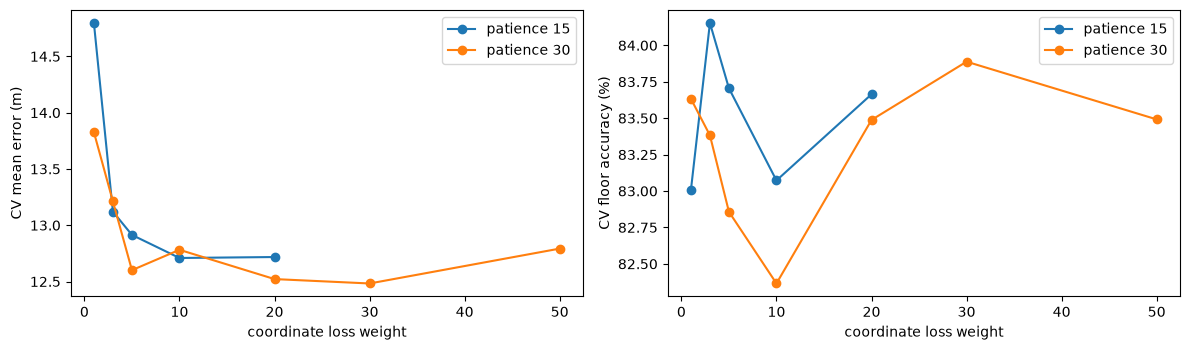

,w_xy,patience,building_acc,floor_acc,mean_error_m
0,1,15,0.971,0.830,14.796
1,1,30,0.973,0.836,13.826
2,3,15,0.963,0.842,13.121
3,3,30,0.954,0.834,13.212
4,5,15,0.957,0.837,12.914
5,5,30,0.967,0.829,12.601
6,10,15,0.982,0.831,12.709
7,10,30,0.963,0.824,12.782
8,20,15,0.960,0.837,12.718
9,20,30,0.965,0.835,12.522


In [4]:
tuning = pd.read_csv(RES / "dl_tuning.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for p, d in tuning.groupby("patience"):
    ax[0].plot(d.w_xy, d.mean_error_m, marker="o", label=f"patience {p}")
    ax[1].plot(d.w_xy, d.floor_acc * 100, marker="o", label=f"patience {p}")
ax[0].set_xlabel("coordinate loss weight"); ax[0].set_ylabel("CV mean error (m)"); ax[0].legend()
ax[1].set_xlabel("coordinate loss weight"); ax[1].set_ylabel("CV floor accuracy (%)"); ax[1].legend()
plt.tight_layout(); plt.show()
tuning[["w_xy", "patience", "building_acc", "floor_acc", "mean_error_m"]]

For reference, the Phase 1 cross-validation numbers were: k-NN 74.1% floor and 11.78 m; per-building Random Forest 71.3% floor and 13.55 m.

## 4. Train the final network on all training data and test once

In [5]:
model = MultitaskModel(**settings).fit(Xtr, ytr, groups=mtr["USERID"].to_numpy())
pred = model.predict(Xte)
dl = summarize(yte, pred)
print("epochs run:", model.epochs_run_)
print(model.model_)
{k: round(v, 3) for k, v in dl.items()}

epochs run: 108
MultitaskMLP(
  (trunk): Sequential(
    (0): Linear(in_features=465, out_features=1024, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
  )
  (head_building): Linear(in_features=256, out_features=3, bias=True)
  (head_floor): Linear(in_features=256, out_features=5, bias=True)
  (head_xy): Linear(in_features=256, out_features=2, bias=True)
)


{'building_acc': np.float64(1.0),
 'floor_acc': np.float64(0.923),
 'building_floor_acc': np.float64(0.923),
 'mae_longitude_m': np.float64(5.987),
 'mae_latitude_m': np.float64(5.118),
 'mean_error_m': np.float64(8.661),
 'median_error_m': np.float64(6.881),
 'p75_error_m': np.float64(11.048),
 'p95_error_m': np.float64(20.765)}

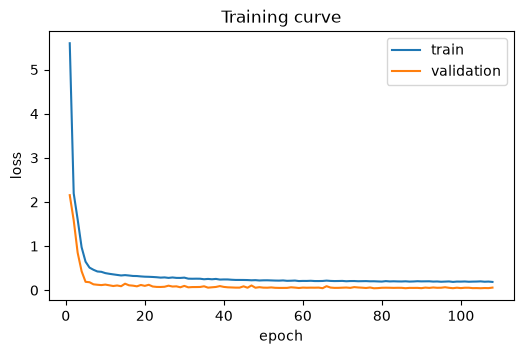

In [6]:
h = pd.DataFrame(model.history_)
plt.figure(figsize=(6, 3.5))
plt.plot(h.epoch, h.train_loss, label="train")
plt.plot(h.epoch, h.val_loss, label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Training curve"); plt.legend()
plt.show()

## 5. Phase 1 vs Phase 2 on the test set

In [7]:
cmp = pd.concat([phase1, pd.DataFrame([{"model": "Multitask MLP (Phase 2)", **dl}])], ignore_index=True)
cmp = cmp.set_index("model")
cmp[["building_acc", "floor_acc", "building_floor_acc", "mae_longitude_m", "mae_latitude_m", "mean_error_m", "median_error_m", "p95_error_m"]]

,building_acc,floor_acc,building_floor_acc,mae_longitude_m,mae_latitude_m,mean_error_m,median_error_m,p95_error_m
model,,,,,,,,
Linear + Logistic Regression,1.000,0.887,0.887,43.695,24.670,51.995,37.528,141.884
k-NN,0.997,0.901,0.901,5.805,5.353,8.691,5.355,26.992
Random Forest,0.998,0.909,0.908,6.821,6.196,10.222,7.629,27.419
Random Forest (per-building),0.998,0.913,0.912,6.193,5.769,9.366,7.073,23.311
Multitask MLP (Phase 2),1.000,0.923,0.923,5.987,5.118,8.661,6.881,20.765


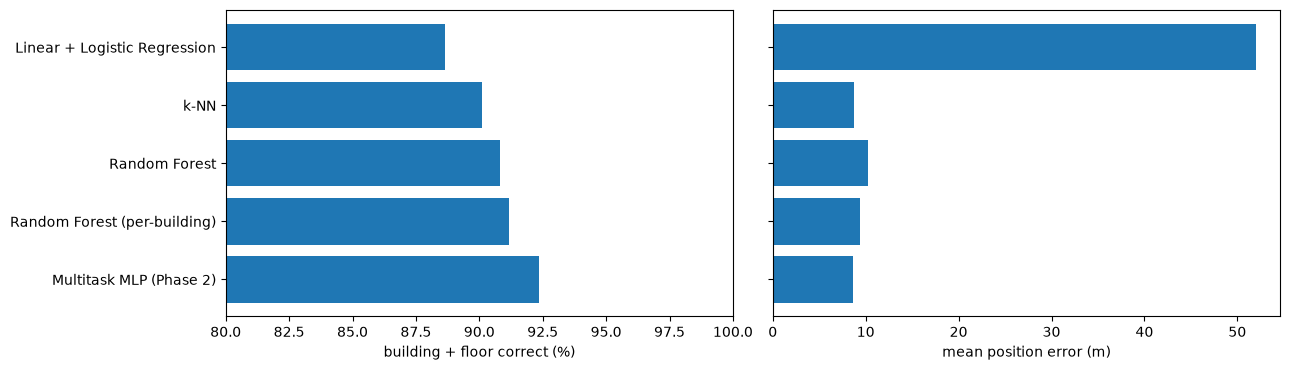

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].barh(cmp.index, cmp.building_floor_acc * 100); ax[0].set_xlim(80, 100)
ax[0].set_xlabel("building + floor correct (%)"); ax[0].invert_yaxis()
ax[1].barh(cmp.index, cmp.mean_error_m); ax[1].set_xlabel("mean position error (m)")
ax[1].invert_yaxis(); ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

## 6. Error analysis of the network

In [9]:
hierarchical_breakdown(yte, pred)

,case,count,mean,median,share_of_total_error
0,"building ok, floor ok",1026,7.992,6.597,0.852
1,"building ok, floor wrong",85,16.740,11.867,0.148


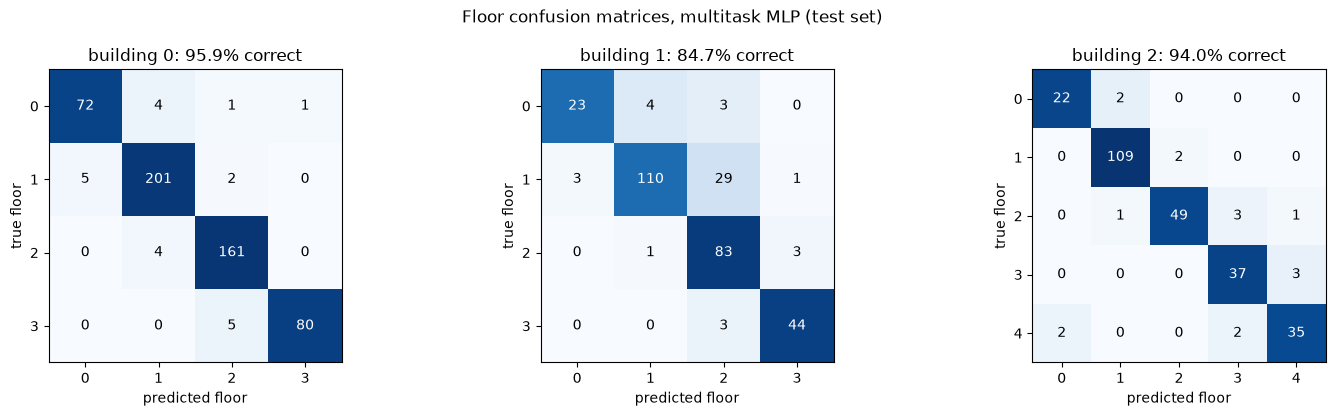

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for b in range(3):
    m = yte.BUILDINGID.to_numpy() == b
    floors = sorted(yte.loc[m, "FLOOR"].unique())
    cm = confusion_matrix(yte.loc[m, "FLOOR"], pred["FLOOR"][m], labels=floors)
    ax[b].imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(len(floors)):
        for j in range(len(floors)):
            ax[b].text(j, i, cm[i, j], ha="center", va="center",
                       color="white" if cm[i, j] > cm[i].sum() * 0.55 else "black")
    ax[b].set_xticks(range(len(floors)), floors); ax[b].set_yticks(range(len(floors)), floors)
    ax[b].set_xlabel("predicted floor"); ax[b].set_ylabel("true floor")
    ax[b].set_title(f"building {b}: {np.trace(cm) / cm.sum() * 100:.1f}% correct")
plt.suptitle("Floor confusion matrices, multitask MLP (test set)")
plt.tight_layout(); plt.show()

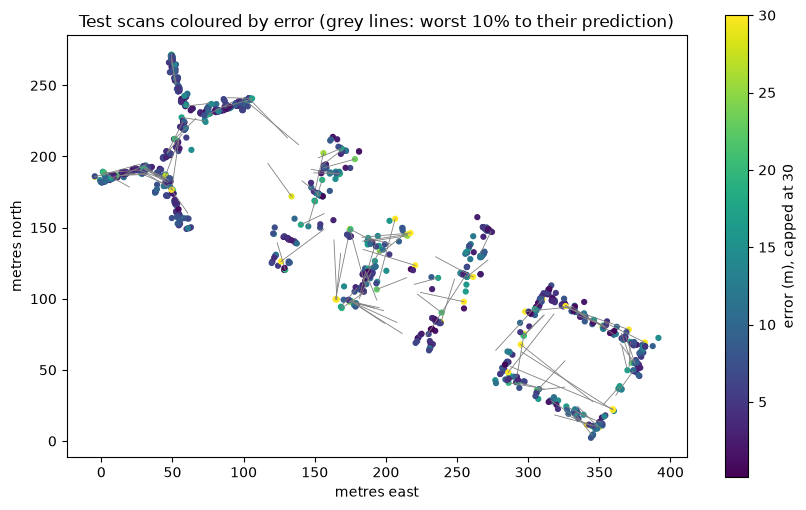

In [11]:
x0, y0 = train.LONGITUDE.min(), train.LATITUDE.min()
err = positioning_errors(yte, pred)
tx, ty = yte.LONGITUDE - x0, yte.LATITUDE - y0
px, py = pred["LONGITUDE"] - x0, pred["LATITUDE"] - y0
plt.figure(figsize=(10, 6))
for i in np.flatnonzero(err > np.percentile(err, 90)):
    plt.plot([tx.iloc[i], px[i]], [ty.iloc[i], py[i]], color="grey", linewidth=0.6)
plt.scatter(tx, ty, c=np.clip(err, 0, 30), cmap="viridis", s=12)
plt.colorbar(label="error (m), capped at 30")
plt.gca().set_aspect("equal"); plt.xlabel("metres east"); plt.ylabel("metres north")
plt.title("Test scans coloured by error (grey lines: worst 10% to their prediction)")
plt.show()

In [12]:
per_group_error(yte, pred, mte["PHONEID"])

,PHONEID,n,mean_error_m,median_error_m,building_floor_acc
0,0,120,7.646,5.841,0.908
1,2,52,10.133,7.145,0.865
2,4,69,7.271,6.439,0.942
3,5,17,10.395,7.370,0.647
4,9,77,6.655,5.988,0.974
5,12,70,8.581,7.339,0.914
6,13,369,6.974,5.537,0.954
7,14,28,15.191,10.094,0.821
8,15,36,7.915,7.755,0.944
9,20,213,11.611,9.321,0.892


## 7. Regularisation, ablations and hybrid

These come from the teammates' scripts (`run_dl_regularisation.py`, `run_dl_ablations.py`, `run_hybrid.py`).
The cells below show the tables when the result files exist.

In [13]:
for name, cols in [("dl_regularisation.csv", ["scaler", "dropout", "weight_decay", "floor_acc", "mean_error_m"]),
                   ("dl_ablations.csv", ["ablation", "setting", "floor_acc", "mean_error_m"]),
                   ("hybrid.csv", ["model", "cv_floor_acc", "cv_mean_error_m", "test_floor_acc", "test_mean_error_m"])]:
    p = RES / name
    if p.exists():
        d = pd.read_csv(p)
        print(name)
        display(d[[c for c in cols if c in d.columns]].round(3))
    else:
        print(name, ": not available yet")

dl_regularisation.csv : not available yet
dl_ablations.csv : not available yet
hybrid.csv : not available yet


## 8. Summary

- One network with a shared trunk and three heads replaces the three separate Phase 1 models.
- On the test set it reaches 100% building, 92.3% floor and 8.66 m mean position error, with the smallest worst-case errors of any model (20.8 m at the 95th percentile). Phase 1's best floor accuracy was 91.3% (per-building Random Forest). On mean error it ties with k-NN (8.69 m); k-NN still has the lowest median (5.36 m against 6.88 m).
- In cross-validation by user the lead is clearer: 83.1% floor and 11.17 m, against 74.1% and 11.78 m for k-NN and 71.3% and 13.55 m for the per-building forest.
- Two things made the difference. Early stopping has to be judged on a representative validation set (a random 10% of training scans), not on one or two held-out users. And the coordinate loss needs a high weight (20) so the position head is actually trained; with equal weights the two classification losses dominate.
- The wider trunk (1024, 512, 256) was the architecture change that mattered. Batch normalisation and more dropout did not help; a correctly scaled Huber loss was a tie with MSE, so we kept MSE.
- Errors still depend on the phone: 6.7 m on the best test phone (phone 9) and 15.2 m on the worst (phone 14), with 9 of 11 test phones unseen in training. That is the same pattern as Phase 1.
- The ablations, the regularisation sweep and the hybrid (section 7) are run by the rest of the team from these settings.